# Paper 19: Representation Learning with Contrastive Predictive Coding (CPC / InfoNCE)
**Authors**: Aaron van den Oord, Yazhe Li, Oriol Vinyals (DeepMind, 2018)

---

## 1. The Historical Breaking Point: Pixel Reconstruction Noise
Before CPC, unsupervised representation learning tried to predict raw future observations $p(x_{t+k} \mid c_t)$ directly in pixel/waveform space. That forced models to waste capacity on unpredictable local high-frequency noise instead of learning abstract semantic structure.

## 2. The Thought Experiment: Contrastive Guessing & InfoNCE
Instead of generating future raw data, CPC predicts future **latent representations** $z_{t+k}$ by contrasting the single true future latent against $N-1$ negative distractors:
$$\mathcal{L}_N = -\mathbb{E}_X \left[ \log \frac{\exp(\hat{z}_{t+k}^T z_{t+k} / \tau)}{\sum_{j=1}^N \exp(\hat{z}_{t+k}^T z_j / \tau)} \right]$$

Crucially, minimizing $\mathcal{L}_N$ maximizes a **lower bound on Mutual Information**:
$$I(x_{t+k}; c_t) \ge \log(N) - \mathcal{L}_N$$

In this notebook, you will explore:
1. InfoNCE and the $\log(N)$ Mutual Information bound
2. Autoregressive context causality
3. Temporal representation learning and similarity matrix emergence

---
## Setup & Autoreload

In [2]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    info_nce_loss,
    CPCEncoder,
    CPCModel,
)

print(f"PyTorch version: {torch.__version__}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch version: 2.14.1+cpu


---
## 1. The InfoNCE Mutual Information Bound: $\log(N) - \mathcal{L}_N$
When queries and keys are uncorrelated ($I = 0$), InfoNCE loss equals $\log(N)$. As $N$ (batch size / number of negatives) grows, the bound tightens!

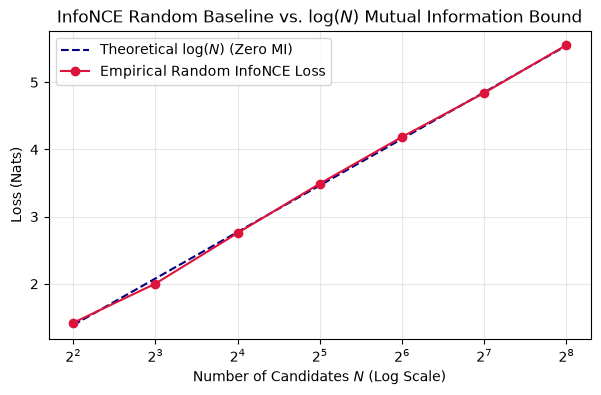

In [3]:
torch.manual_seed(42)
batch_sizes = [4, 8, 16, 32, 64, 128, 256]
random_losses = []
theoretical_bounds = []

for N in batch_sizes:
    q = torch.randn(N, 64)
    k = torch.randn(N, 64)
    loss, _ = info_nce_loss(q, k, temperature=0.5, normalize=True)
    random_losses.append(loss.item())
    theoretical_bounds.append(math.log(N))

plt.figure(figsize=(7, 4))
plt.plot(batch_sizes, theoretical_bounds, "--", label="Theoretical $\\log(N)$ (Zero MI)", color="navy")
plt.plot(batch_sizes, random_losses, "o-", label="Empirical Random InfoNCE Loss", color="crimson")
plt.xscale("log", base=2)
plt.xlabel("Number of Candidates $N$ (Log Scale)")
plt.ylabel("Loss (Nats)")
plt.title("InfoNCE Random Baseline vs. $\\log(N)$ Mutual Information Bound")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

---
## 2. Training CPC on Multi-Frequency Temporal Waves
Let's train `CPCModel` to predict future latent states $k \in \{1, 2, 3\}$ steps ahead on phase-shifted sinusoidal sequences.

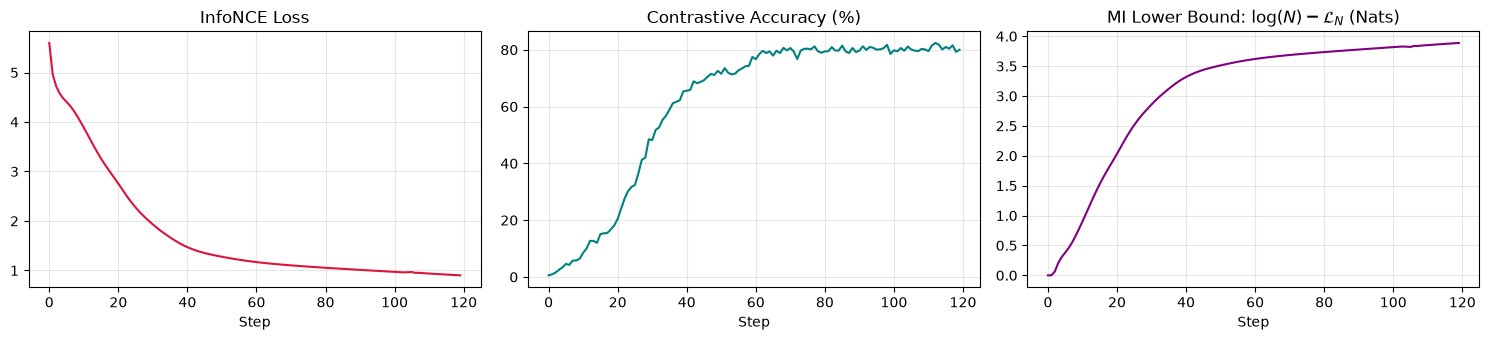

In [4]:
torch.manual_seed(42)
B, L, D_in = 8, 16, 8
t = torch.linspace(0, 4 * math.pi, L).unsqueeze(0).unsqueeze(-1)
phases = torch.linspace(0, 2 * math.pi, B).unsqueeze(1).unsqueeze(-1)
freqs = torch.arange(1, D_in + 1, dtype=torch.float32).view(1, 1, D_in) * 0.5
x = torch.sin(t * freqs + phases)

model = CPCModel(input_dim=D_in, latent_dim=32, context_dim=32, prediction_steps=3, temperature=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3)

losses, accs, mi_bounds = [], [], []
N_candidates = B * (L - 1)
log_N = math.log(N_candidates)

for step in range(120):
    optimizer.zero_grad()
    loss, acc, z, c = model(x)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    accs.append(acc.item() * 100)
    mi_bounds.append(max(0.0, log_N - loss.item()))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(losses, color="crimson")
axes[0].set_title("InfoNCE Loss")
axes[0].set_xlabel("Step")
axes[0].grid(True, alpha=0.3)

axes[1].plot(accs, color="teal")
axes[1].set_title("Contrastive Accuracy (%)")
axes[1].set_xlabel("Step")
axes[1].grid(True, alpha=0.3)

axes[2].plot(mi_bounds, color="purple")
axes[2].set_title("MI Lower Bound: $\\log(N) - \\mathcal{L}_N$ (Nats)")
axes[2].set_xlabel("Step")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Visualizing the Learned Similarity Matrix ($k=1$ Step Ahead)
A well-trained CPC model produces a sharp diagonal line in the similarity matrix $\hat{z}_{t+1} \cdot z_{t+1}^T$, showing it can uniquely pinpoint the true future latent among all other timesteps and batch items.

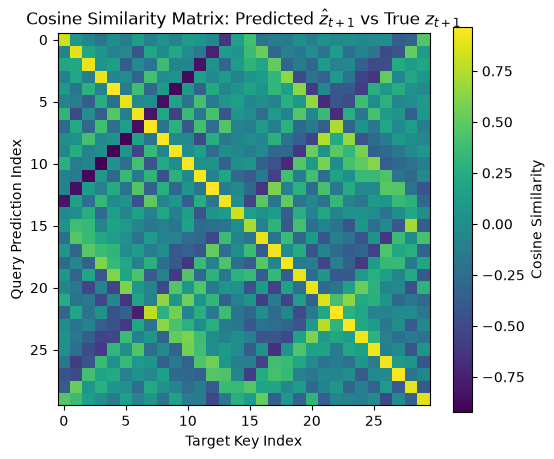

In [5]:
model.eval()
with torch.no_grad():
    z, c = model.encode(x)
    c_t = c[:, :-1, :].reshape(-1, model.context_dim)
    z_future = z[:, 1:, :].reshape(-1, model.latent_dim)
    z_pred = model.predictors[0](c_t)

    q_norm = F.normalize(z_pred[:30], dim=-1)
    k_norm = F.normalize(z_future[:30], dim=-1)
    sim_matrix = torch.matmul(q_norm, k_norm.T).cpu().numpy()

plt.figure(figsize=(6, 5))
plt.imshow(sim_matrix, cmap="viridis")
plt.colorbar(label="Cosine Similarity")
plt.title("Cosine Similarity Matrix: Predicted $\\hat{z}_{t+1}$ vs True $z_{t+1}$")
plt.xlabel("Target Key Index")
plt.ylabel("Query Prediction Index")
plt.show()